# Compare 1984 perturbation results: 10-member ensemble mean vs. single member 2

Both pipelines perturb the **exact same real ERA5 archive** with a stage-03 delta, and both were run for the same `--years 1984` window. The only difference is *which* future-minus-current LENS2 warming signal gets added:

- **ens10** (`/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10`, perturbed output under `.../wpsv4.5_mpas_LENS2PGW_ens10mean`): the **10-member smbb-ensemble mean** climatology delta -- each of 10 LENS2 members' own 30-year climatology averaged together before differencing future minus current.
- **mem2** (`/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW`, perturbed output under `.../wpsv4.5_mpas_LENS2PGW_mem2`): a **single member's own** climatology delta -- LENS2 case `1031.002` ("member 2" in this project family's numbering), no ensemble averaging.

Averaging across 10 members should cancel out much of each member's own internal (weather/decadal) variability, leaving mostly the shared, externally-forced SSP370 warming signal. A single member's climatology still contains its own share of that internal variability baked in. Comparing the two shows how much they agree on the large-scale pattern versus how much a single realization can differ from the ensemble-mean signal.

Two independent comparisons, covering both streams stage 04 (`04_apply_perturbation.py`) produces:

- **Part A**: the main `ERA5:1984-06-*` archive -- `GHT`, `TT`, `RH` (3-D, all 37 pressure levels) and `SKINTEMP`, `SST` (surface).
- **Part B**: the periodic `SST_UPDATE:*` stream (`ERA5_SST:*` on disk) -- a separate file layout/land-mask, `SST` only, but with a much longer 1984 test window (June-December, 184 days) than the main archive's 6 June days.

## Setup

Both projects have a `config.py` module -- to load both without one clobbering the other in `sys.modules`, `config.py` (a leaf module: it only imports `pathlib`/`numpy`, never `config` or `lib` itself) is loaded twice under distinct names via `importlib`. `04_apply_perturbation.py`'s shared constants/functions (`SST_FLOOR_K`, `SST_FILL_THRESHOLD`, the SST-update filename regexes, `load_ocean_mask()`) only depend on `config.ERA5_IM_DIR`, which is verified below to be identical between the two projects, so this project's copy is reused for both rather than loading a second one.

In [1]:
import sys
sys.path.insert(0, "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10")  # so `import config`/`lib` below resolve

import datetime as dt
import glob
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import config as config_ens10       # this project: 10-member ensemble mean
import lib.wps_intermediate as wps  # binary WPS-intermediate-file reader (byte-identical copy in both projects)

# apply_pgw's SST_FLOOR_K / SST_FILL_THRESHOLD / SST-update filename regexes / load_ocean_mask()
# are pipeline-agnostic logic parameterized only by config.ERA5_IM_DIR -- verified identical
# between the two projects below, so reusing this one copy for both pipelines is correct,
# not an assumption.
_spec = importlib.util.spec_from_file_location(
    "apply_pgw", "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10/04_apply_perturbation.py")
apply_pgw = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(apply_pgw)

# config.py has no internal "import config"/"import lib" of its own, so loading the sibling
# single-member project's config.py under a distinct module name ("config_mem2") is safe --
# it cannot collide with config_ens10 above the way importing two same-named packages would.
_spec2 = importlib.util.spec_from_file_location(
    "config_mem2", "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW/config.py")
config_mem2 = importlib.util.module_from_spec(_spec2)
_spec2.loader.exec_module(config_mem2)

print("ens10 (10-member ensemble mean):")
print("  perturbed dir:", config_ens10.PERTURBED_IM_DIR)
print("  delta dir:    ", config_ens10.DELTA_DIR)
print("mem2 (single member 1031.002, \"member 2\"):")
print("  perturbed dir:", config_mem2.PERTURBED_IM_DIR)
print("  delta dir:    ", config_mem2.DELTA_DIR)

ens10 (10-member ensemble mean):
  perturbed dir: /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean
  delta dir:     /glade/derecho/scratch/mingge/MPAS_LENS2_PGW_ENS10/03_delta
mem2 (single member 1031.002, "member 2"):
  perturbed dir: /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_mem2
  delta dir:     /glade/derecho/scratch/mingge/MPAS_LENS2_PGW/03_delta


## Verify the shared inputs

Confirm -- rather than assume -- that both pipelines really do perturb the same source archive/grid and touch the same set of fields, so any difference found below is attributable to the delta, not to different inputs or different perturbation targets.

In [2]:
assert config_ens10.ERA5_IM_DIR == config_mem2.ERA5_IM_DIR, \
    "the two pipelines perturb different source archives -- comparison would not be apples-to-apples"
assert (config_ens10.ERA5_NX, config_ens10.ERA5_NY) == (config_mem2.ERA5_NX, config_mem2.ERA5_NY)
assert np.array_equal(config_ens10.ERA5_LAT, config_mem2.ERA5_LAT)
assert np.array_equal(config_ens10.ERA5_LON, config_mem2.ERA5_LON)
assert config_ens10.PERTURB_FIELDS_3D == config_mem2.PERTURB_FIELDS_3D
assert config_ens10.PERTURB_FIELDS_SFC == config_mem2.PERTURB_FIELDS_SFC
print("OK: both pipelines read the identical source archive/grid and perturb the identical field set:")
print(" ", config_ens10.ERA5_IM_DIR)
print(" 3-D:", config_ens10.PERTURB_FIELDS_3D, " surface:", list(config_ens10.PERTURB_FIELDS_SFC))

ORIG_DIR = config_ens10.ERA5_IM_DIR   # shared -- either project's copy of this path is fine
lat, lon = config_ens10.ERA5_LAT, config_ens10.ERA5_LON
PERTURBED_3D = set(config_ens10.PERTURB_FIELDS_3D)           # {GHT, TT, RH}
PERTURBED_SFC = set(config_ens10.PERTURB_FIELDS_SFC.keys())  # {SST, SKINTEMP}

# static land/ocean mask (from the main-stream ERA5:* LANDSEA record) -- shared, since it
# only depends on ERA5_IM_DIR which was just verified identical above
ocean_mask = apply_pgw.load_ocean_mask()
land = ~ocean_mask
weights = np.cos(np.deg2rad(lat))[:, None]  # cos(latitude) area weighting, used throughout below
print(f"\nocean fraction: {ocean_mask.mean():.3f}")

OK: both pipelines read the identical source archive/grid and perturb the identical field set:
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas
 3-D: ['GHT', 'TT', 'RH']  surface: ['SST', 'SKINTEMP']



ocean fraction: 0.661


In [3]:
def area_wmean(a, mask=None):
    """Area-weighted (cos-latitude) mean of a 2-D field, optionally restricted to `mask`
    (e.g. ocean-only for SST). Cells outside `mask` get zero weight rather than being
    dropped, so this works directly on the full-grid array without any pre-masking."""
    w = weights if mask is None else np.where(mask, weights, 0.0)
    return float(np.average(a, weights=np.broadcast_to(w, a.shape)))

def corr_rms(a, b, mask=None):
    """Spatial Pearson correlation and RMS difference between two fields, over `mask`
    (or the whole grid if None)."""
    av, bv = (a[mask], b[mask]) if mask is not None else (a.ravel(), b.ravel())
    corr = np.corrcoef(av, bv)[0, 1]
    rms = np.sqrt(np.mean((av - bv) ** 2))
    return corr, rms

def masked(a):
    """NaN out land cells for plotting ocean-only fields (e.g. SST) -- matplotlib leaves
    NaN cells blank instead of drawing a bogus color."""
    return np.where(land, np.nan, a)

# Part A: main `ERA5:1984*` archive

`GHT`, `TT`, `RH` (3-D, 37 pressure levels) and `SKINTEMP`, `SST` (surface). Both pipelines were run with `--years 1984` against the same source archive, which in practice only holds 6 real ERA5 files for June 1984 (`ERA5:1984-06-01_00` through `...-06_00`) -- see `05_verify_perturbation.ipynb` for why (the source archive itself, not either pipeline, only has that much 1984 data in the main stream).

## A1. Discover common test dates and load records

Both pipelines' `PERTURBED_IM_DIR` should hold a perturbed copy of every main-stream `ERA5:1984*` file -- checked rather than assumed, since a partial rerun on either side would silently make some dates one-sided.

In [4]:
def main_stream_dates(pert_dir):
    """date-string ("1984-06-01_00") -> perturbed-file Path, for one pipeline's PERTURBED_IM_DIR."""
    pattern = str(pert_dir / f"{config_ens10.ERA5_IM_PREFIX}:*")
    files = sorted(Path(p) for p in glob.glob(pattern))
    files = [f for f in files if apply_pgw._IM_NAME_RE.match(f.name)]
    return {f.name.split(":")[1]: f for f in files}

ens10_main_files = main_stream_dates(config_ens10.PERTURBED_IM_DIR)
mem2_main_files = main_stream_dates(config_mem2.PERTURBED_IM_DIR)

common_dates_main = sorted(set(ens10_main_files) & set(mem2_main_files))
only_ens10_main = sorted(set(ens10_main_files) - set(mem2_main_files))
only_mem2_main = sorted(set(mem2_main_files) - set(ens10_main_files))

print(f"ens10 main-stream files: {len(ens10_main_files)}")
print(f"mem2  main-stream files: {len(mem2_main_files)}")
print(f"common test dates:      {len(common_dates_main)}")
if only_ens10_main:
    print("dates only in ens10 (skipped below):", only_ens10_main)
if only_mem2_main:
    print("dates only in mem2 (skipped below): ", only_mem2_main)
assert common_dates_main, "no overlapping main-stream test dates between the two pipelines"

ens10 main-stream files: 6
mem2  main-stream files: 51
common test dates:      6
dates only in mem2 (skipped below):  ['1993-06-01_00', '1994-06-01_00', '1994-06-02_00', '1994-06-03_00', '1994-06-04_00', '1994-06-05_00', '1994-06-06_00', '1998-06-01_00', '1998-06-02_00', '1998-06-03_00', '1998-06-04_00', '1998-06-05_00', '1998-06-06_00', '1999-06-01_00', '1999-06-02_00', '1999-06-03_00', '1999-06-04_00', '1999-06-05_00', '1999-06-06_00', '2005-06-01_00', '2008-06-01_00', '2008-06-02_00', '2008-06-03_00', '2008-06-04_00', '2008-06-05_00', '2008-06-06_00', '2012-06-01_00', '2015-06-01_00', '2015-06-02_00', '2015-06-03_00', '2015-06-04_00', '2015-06-05_00', '2015-06-06_00', '2018-06-01_00', '2018-06-02_00', '2018-06-03_00', '2018-06-04_00', '2018-06-05_00', '2018-06-06_00', '2019-06-01_00', '2019-06-02_00', '2019-06-03_00', '2019-06-04_00', '2019-06-05_00', '2019-06-06_00']


In [5]:
def key(rec):
    return (rec.field, round(rec.xlvl, 3))

main_records = []
for date in common_dates_main:
    orig = wps.read_file(ORIG_DIR / f"{config_ens10.ERA5_IM_PREFIX}:{date}")
    ens10_pert = wps.read_file(ens10_main_files[date])
    mem2_pert = wps.read_file(mem2_main_files[date])

    # same record count/order in all three files -- both pipelines started from, and only
    # mutated slab values of, this exact original
    keys = [key(r) for r in orig]
    assert keys == [key(r) for r in ens10_pert], f"{date}: ens10 record order differs from original"
    assert keys == [key(r) for r in mem2_pert], f"{date}: mem2 record order differs from original"

    # every record OUTSIDE the documented perturbation set must be byte-identical to the
    # original in BOTH pipelines' copies -- e.g. UU, VV, PSFC, SEAICE, LANDSEA, soil fields,
    # and the 2 m/10 m surface-sentinel TT/RH records (a different quantity from the 3-D
    # profile, left alone by design, not an oversight)
    for ro, rep, rmp in zip(orig, ens10_pert, mem2_pert):
        is_sfc_sentinel = ro.xlvl == config_ens10.ERA5_SURFACE_LEVEL_PA
        expected_perturbable = (
            (ro.field in PERTURBED_3D and not is_sfc_sentinel) or (ro.field in PERTURBED_SFC)
        )
        if not expected_perturbable:
            assert np.array_equal(ro.slab, rep.slab), \
                f"{date}: ens10 modified {ro.field}@{ro.xlvl} outside the perturbation set"
            assert np.array_equal(ro.slab, rmp.slab), \
                f"{date}: mem2 modified {ro.field}@{ro.xlvl} outside the perturbation set"

    main_records.append(dict(date=date, month=int(date[5:7]), orig=orig,
                              ens10_pert=ens10_pert, mem2_pert=mem2_pert,
                              fields_present={r.field for r in orig}))

months_present_main = sorted({r["month"] for r in main_records})
print(f"loaded {len(main_records)} common main-stream test dates, month(s) {months_present_main}")
print("PASS: record order matches and every non-perturbed field/record is byte-identical to the "
      "original, in both pipelines, every common date.")

loaded 6 common main-stream test dates, month(s) [6]
PASS: record order matches and every non-perturbed field/record is byte-identical to the original, in both pipelines, every common date.


## A2. Load each pipeline's stage-03 delta for every perturbed field

This is the *intended* signal each pipeline adds -- straight from `DELTA_DIR/<month>.nc`, independent of any single date's RH `[0, 100]` clip or SST 271 K floor (both non-linear, value-dependent adjustments applied only at the moment a delta is added to one specific day's data -- see `05_verify_perturbation.ipynb` for why comparing the delta files directly, not `perturbed - original`, is the cleaner quantity here too).

In [6]:
DELTA_FIELDS = ["GHT", "TT", "RH", "SKINTEMP", "SST"]

def load_main_deltas(delta_dir, months):
    out = {}
    lev_pa = None
    for m in months:
        with xr.open_dataset(delta_dir / f"{m:02d}.nc") as ds:
            out[m] = {f: ds[f].values.astype(np.float64) for f in DELTA_FIELDS}
            lev = ds["lev_pa"].values
            lev_pa = lev if lev_pa is None else lev_pa  # same 37 levels every month, take the first
    return out, lev_pa

ens10_main_deltas, lev_pa_ens10 = load_main_deltas(config_ens10.DELTA_DIR, months_present_main)
mem2_main_deltas, lev_pa_mem2 = load_main_deltas(config_mem2.DELTA_DIR, months_present_main)
assert np.array_equal(lev_pa_ens10, lev_pa_mem2), "the two pipelines use different pressure levels!"
lev_pa = lev_pa_ens10
i850 = int(np.argmin(np.abs(lev_pa - 85000)))  # representative level for single-level tables/maps below
print(f"loaded main-stream deltas for month(s) {months_present_main}, {len(lev_pa)} pressure levels")

loaded main-stream deltas for month(s) [6], 37 pressure levels


## A3. Per-field comparison table

3-D fields (`GHT`, `TT`, `RH`) at 850 hPa as a representative level (section A4 below covers the full column); `SKINTEMP` over the whole grid; `SST` restricted to ocean cells.

In [7]:
rows = []
for month in months_present_main:
    e, m = ens10_main_deltas[month], mem2_main_deltas[month]

    for field in ["GHT", "TT", "RH"]:
        e850, m850 = e[field][i850], m[field][i850]
        corr, rms = corr_rms(e850, m850)
        rows.append(dict(month=month, field=f"{field}@850hPa",
                          ens10_mean=area_wmean(e850), mem2_mean=area_wmean(m850),
                          diff=area_wmean(e850) - area_wmean(m850), spatial_corr=corr, rms_diff=rms))

    corr, rms = corr_rms(e["SKINTEMP"], m["SKINTEMP"])
    rows.append(dict(month=month, field="SKINTEMP",
                      ens10_mean=area_wmean(e["SKINTEMP"]), mem2_mean=area_wmean(m["SKINTEMP"]),
                      diff=area_wmean(e["SKINTEMP"]) - area_wmean(m["SKINTEMP"]),
                      spatial_corr=corr, rms_diff=rms))

    corr, rms = corr_rms(e["SST"], m["SST"], ocean_mask)
    rows.append(dict(month=month, field="SST (ocean)",
                      ens10_mean=area_wmean(e["SST"], ocean_mask), mem2_mean=area_wmean(m["SST"], ocean_mask),
                      diff=area_wmean(e["SST"], ocean_mask) - area_wmean(m["SST"], ocean_mask),
                      spatial_corr=corr, rms_diff=rms))

main_field_stats = pd.DataFrame(rows).set_index(["month", "field"]).round(3)
main_field_stats

ens10_mean  mem2_mean   diff  spatial_corr  rms_diff
month field                                                            
6     GHT@850hPa       22.140     22.645 -0.505         0.932     6.604
      TT@850hPa         3.723      3.773 -0.050         0.956     0.321
      RH@850hPa        -2.428     -2.360 -0.068         0.927     1.716
      SKINTEMP          3.219      3.308 -0.089         0.991     0.324
      SST (ocean)       2.256      2.339 -0.083         0.995     0.153

## A4. Vertical profile: ens10 vs. mem2, full column

Global-mean (`TT`, `GHT`) / ocean-mean (n/a here, `RH` is global too) applied delta at every one of the 37 pressure levels -- the 850 hPa row above is just one point on each of these curves.

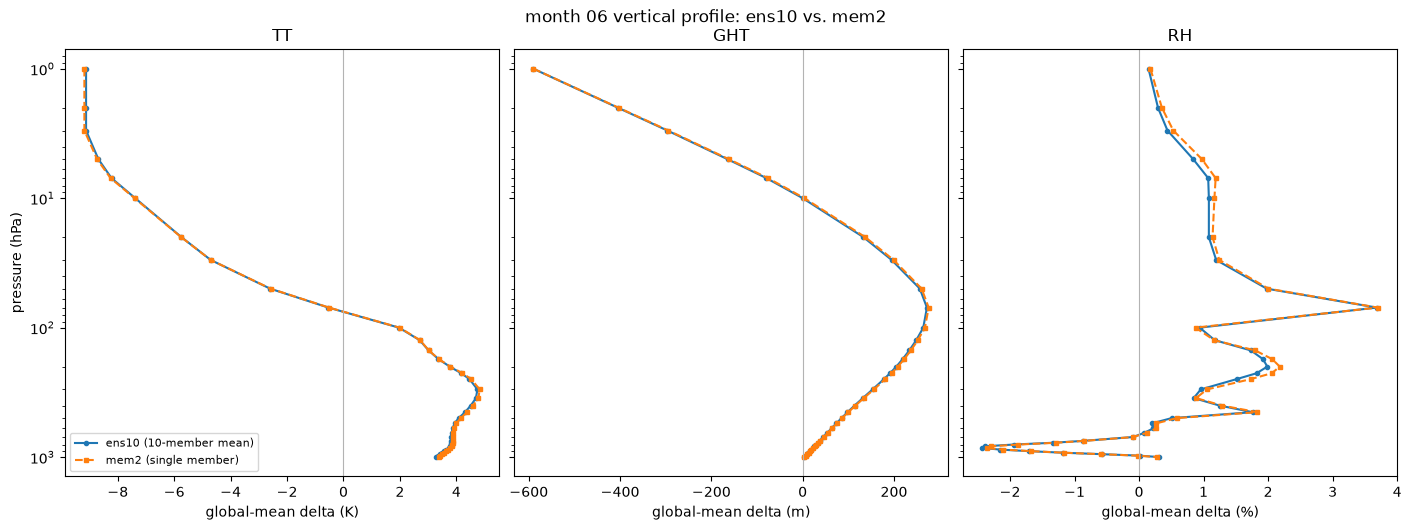

In [8]:
def profile(deltas_by_month, month, field):
    d = deltas_by_month[month][field]  # (nlev, ny, nx)
    return np.array([area_wmean(d[i]) for i in range(d.shape[0])])

month0_main = months_present_main[0]
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True, constrained_layout=True)
for ax, field, unit in zip(axes, ["TT", "GHT", "RH"], ["K", "m", "%"]):
    ax.plot(profile(ens10_main_deltas, month0_main, field), lev_pa / 100, "o-",
            label="ens10 (10-member mean)", ms=3)
    ax.plot(profile(mem2_main_deltas, month0_main, field), lev_pa / 100, "s--",
            label="mem2 (single member)", ms=3)
    ax.axvline(0, color="0.7", lw=0.8)
    ax.set_yscale("log")
    ax.invert_yaxis()  # pressure decreases upward -- surface at the bottom of the plot
    ax.set_xlabel(f"global-mean delta ({unit})")
    ax.set_title(field)
axes[0].set_ylabel("pressure (hPa)")
axes[0].legend(fontsize=8)
fig.suptitle(f"month {month0_main:02d} vertical profile: ens10 vs. mem2", y=1.03)
plt.show()

## A5. Maps: ens10 vs. mem2 vs. their difference

850 hPa for the 3-D fields, plus `SKINTEMP` (land + ocean) and `SST` (ocean only, land masked).

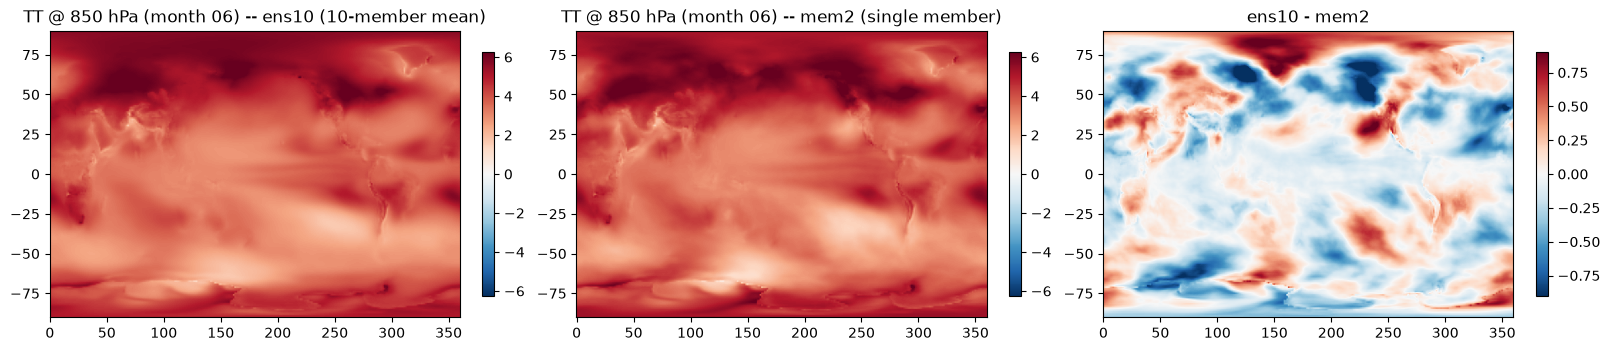

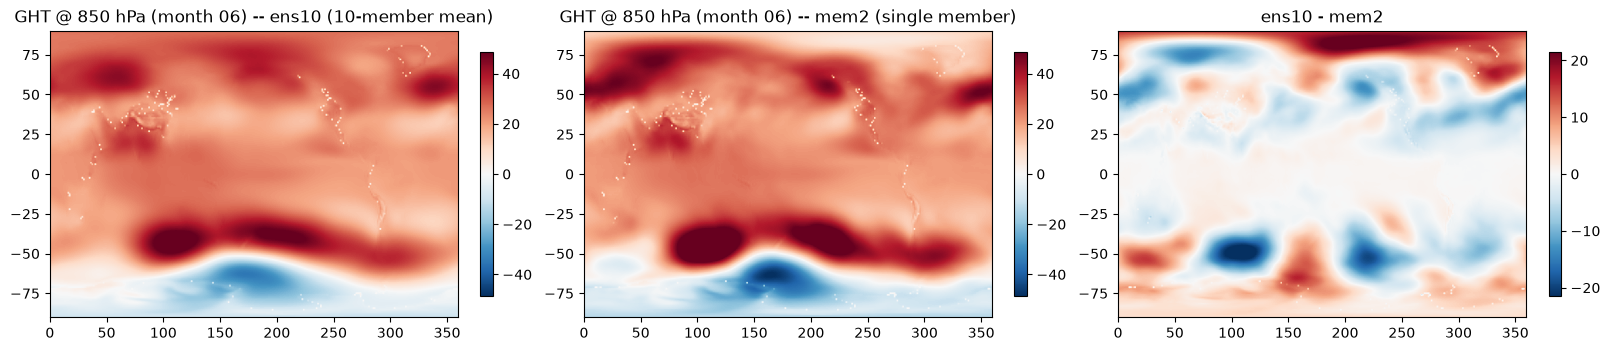

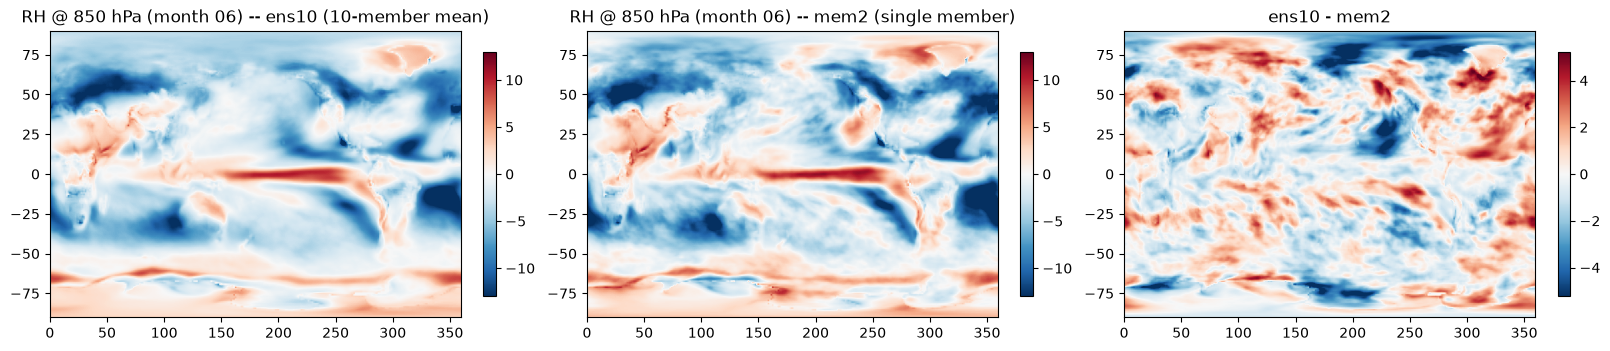

In [9]:
def plot_pair_diff(e, m, title, mask_land=False):
    show = masked if mask_land else (lambda a: a)
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), constrained_layout=True)
    vmax = np.nanpercentile(np.abs(show(e)), 99)
    for ax, data, lbl in zip(axes[:2], [e, m], ["ens10 (10-member mean)", "mem2 (single member)"]):
        im = ax.pcolormesh(lon, lat, show(data), vmin=-vmax, vmax=vmax, cmap="RdBu_r", shading="auto")
        ax.set_title(f"{title} -- {lbl}")
        fig.colorbar(im, ax=ax, shrink=0.85)
    diff = show(e - m)
    dvmax = np.nanpercentile(np.abs(diff), 99)
    im = axes[2].pcolormesh(lon, lat, diff, vmin=-dvmax, vmax=dvmax, cmap="RdBu_r", shading="auto")
    axes[2].set_title("ens10 - mem2")
    fig.colorbar(im, ax=axes[2], shrink=0.85)
    plt.show()

for field in ["TT", "GHT", "RH"]:
    plot_pair_diff(ens10_main_deltas[month0_main][field][i850], mem2_main_deltas[month0_main][field][i850],
                   f"{field} @ 850 hPa (month {month0_main:02d})")

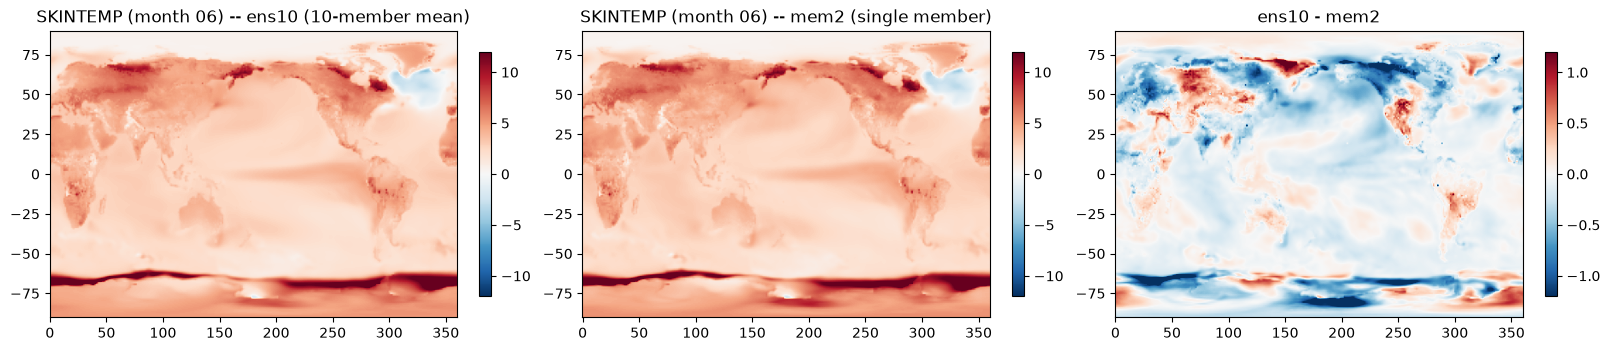

In [10]:
plot_pair_diff(ens10_main_deltas[month0_main]["SKINTEMP"], mem2_main_deltas[month0_main]["SKINTEMP"],
               f"SKINTEMP (month {month0_main:02d})")

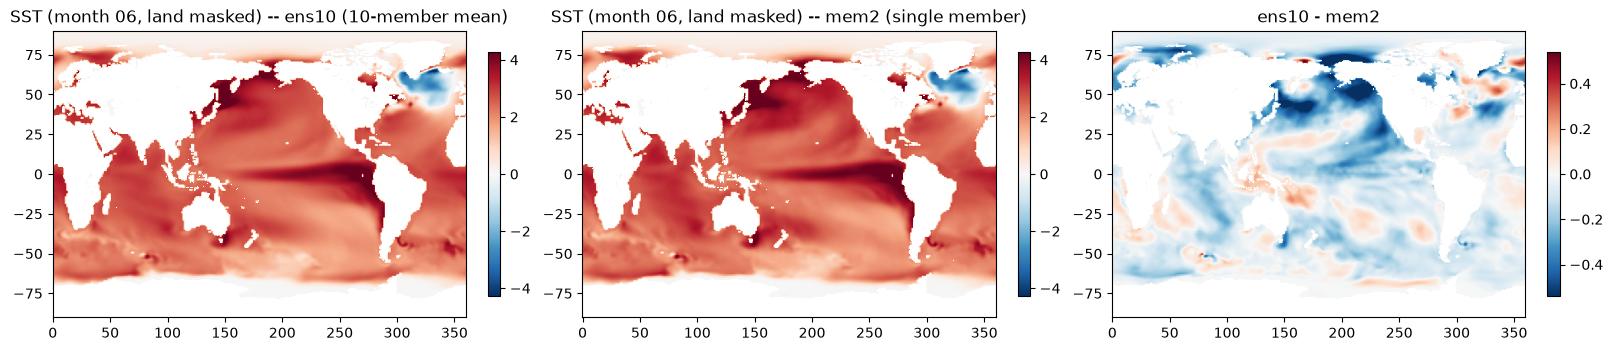

In [11]:
plot_pair_diff(ens10_main_deltas[month0_main]["SST"], mem2_main_deltas[month0_main]["SST"],
               f"SST (month {month0_main:02d}, land masked)", mask_land=True)

# Part B: periodic SST-update stream (`ERA5_SST:*` -> `SST_UPDATE:*`)

A separate file layout from the main archive (`config.ERA5_IM_DIR/SST_<year>/ERA5_SST:<date>`, one `SST` record per file, no land-fill sentinel -- see `05_verify_perturbation.ipynb`). Both pipelines were run for the same `--years 1984` window here too, but this stream has far more 1984 data available (184 days, June-December) than the main archive's 6 June days in Part A, so the comparison below is a much stronger, near-annual test of how the two pipelines' SST signals relate.

## B1. Discover the common SST-update test dates

Each pipeline's `PERTURBED_IM_DIR/SST_1984/` holds one `SST_UPDATE:<date>` per day it processed -- checked rather than assumed, since a partial rerun on either side would silently make some dates one-sided.

In [12]:
def sst_update_dates(pert_dir):
    """date-string ("1984-06-01_00") -> perturbed-file Path, for one pipeline's PERTURBED_IM_DIR."""
    pattern = str(pert_dir / "SST_*" / f"{apply_pgw._SST_UPDATE_PREFIX}:*")
    files = sorted(Path(p) for p in glob.glob(pattern))
    return {f.name.split(":")[1]: f for f in files}

ens10_files = sst_update_dates(config_ens10.PERTURBED_IM_DIR)
mem2_files = sst_update_dates(config_mem2.PERTURBED_IM_DIR)

common_dates = sorted(set(ens10_files) & set(mem2_files))
only_ens10 = sorted(set(ens10_files) - set(mem2_files))
only_mem2 = sorted(set(mem2_files) - set(ens10_files))

print(f"ens10 SST-update files: {len(ens10_files)}")
print(f"mem2  SST-update files: {len(mem2_files)}")
print(f"common test dates:      {len(common_dates)}")
if only_ens10:
    print("dates only in ens10 (skipped below):", only_ens10)
if only_mem2:
    print("dates only in mem2 (skipped below, e.g. other years mem2 also processed):", only_mem2[:6],
          "..." if len(only_mem2) > 6 else "")
assert common_dates, "no overlapping SST-update test dates between the two pipelines"

ens10 SST-update files: 184
mem2  SST-update files: 2114
common test dates:      184
dates only in mem2 (skipped below, e.g. other years mem2 also processed): ['1993-06-01_00', '1993-06-02_00', '1993-06-03_00', '1993-06-04_00', '1993-06-05_00', '1993-06-06_00'] ...


## B2. Load both pipelines' perturbed records and compute the applied delta

For each common date: read the shared original record once, then each pipeline's perturbed copy, and compute `applied = perturbed - original` for both. These are used only for the structural/floor checks in B3 -- the actual signal comparison (B4 onward) uses the stage-03 delta files directly, for the same reason as Part A.

In [13]:
def orig_path_for(pert_path, orig_dir):
    """Invert the SST_UPDATE:<date> -> ERA5_SST:<date> rename stage 04 applies on write,
    to find the shared original file a perturbed copy was built from."""
    orig_name = apply_pgw._SST_UPDATE_SRC_PREFIX + pert_path.name[len(apply_pgw._SST_UPDATE_PREFIX):]
    rel_dir = pert_path.parent.name  # e.g. "SST_1984", the same subdirectory name on both sides
    return orig_dir / rel_dir / orig_name

records = []
for date in common_dates:
    ens10_pert = wps.read_file(ens10_files[date])[0]
    mem2_pert = wps.read_file(mem2_files[date])[0]

    # both pipelines must resolve to the SAME original file for this date -- if they didn't,
    # the two "applied" deltas below wouldn't be comparable at all
    ens10_orig_path = orig_path_for(ens10_files[date], ORIG_DIR)
    mem2_orig_path = orig_path_for(mem2_files[date], ORIG_DIR)
    assert ens10_orig_path == mem2_orig_path, f"{date}: pipelines resolved different original files"
    orig = wps.read_file(ens10_orig_path)[0]

    ens10_delta = ens10_pert.slab.astype(np.float64) - orig.slab.astype(np.float64)
    mem2_delta = mem2_pert.slab.astype(np.float64) - orig.slab.astype(np.float64)

    records.append(dict(date=date, month=int(date[5:7]), orig=orig,
                         ens10_pert=ens10_pert, mem2_pert=mem2_pert,
                         ens10_delta=ens10_delta, mem2_delta=mem2_delta))

months_present = sorted({r["month"] for r in records})
print(f"loaded {len(records)} common test dates spanning months {months_present}")

loaded 184 common test dates spanning months [6, 7, 8, 9, 10, 11, 12]


## B3. Structural sanity checks (both pipelines)

Two checks that don't depend on which delta is "correct", just that both pipelines behaved as documented: land cells untouched, and the 271 K floor never breached.

In [14]:
for r in records:
    assert np.array_equal(r["orig"].slab[land], r["ens10_pert"].slab[land]), \
        f"{r['date']}: ens10 modified a land cell"
    assert np.array_equal(r["orig"].slab[land], r["mem2_pert"].slab[land]), \
        f"{r['date']}: mem2 modified a land cell"
print("PASS: land cells untouched by both pipelines, every common test date.")

ens10_floor_ok = all(r["ens10_pert"].slab[ocean_mask].min() >= apply_pgw.SST_FLOOR_K - 1e-3 for r in records)
mem2_floor_ok = all(r["mem2_pert"].slab[ocean_mask].min() >= apply_pgw.SST_FLOOR_K - 1e-3 for r in records)
assert ens10_floor_ok and mem2_floor_ok, "271 K floor breached in one of the two pipelines"
print("PASS: 271 K floor respected by both pipelines, every common test date.")

# NOTE on what varies day-to-day vs. month-to-month: the *stage-03 delta* each pipeline
# adds is a pure function of calendar month (loaded directly from DELTA_DIR/<month>.nc
# below), but the *applied* result (perturbed - original) is NOT quite the same thing on
# every day of a month -- wherever the 271 K floor kicks in, applied = floor - original,
# and `original` (that day's real archived SST-update value) does vary day to day. So the
# *intended signal* is monthly-constant; only its floor-clamped edge cases differ by date.
# B4 onward compares the intended monthly signal directly from the delta files (not
# reconstructed from perturbed-original), which is the cleaner, floor-independent quantity.
n_floor_clamped_ens10 = sum(int((r["ens10_pert"].slab[ocean_mask] <= apply_pgw.SST_FLOOR_K + 1e-3).sum())
                            for r in records)
n_floor_clamped_mem2 = sum(int((r["mem2_pert"].slab[ocean_mask] <= apply_pgw.SST_FLOOR_K + 1e-3).sum())
                           for r in records)
n_ocean_cell_dates = len(records) * int(ocean_mask.sum())
print(f"floor-clamped ocean-cell/date combinations: ens10 {n_floor_clamped_ens10}/{n_ocean_cell_dates} "
      f"({100 * n_floor_clamped_ens10 / n_ocean_cell_dates:.1f}%), mem2 {n_floor_clamped_mem2}/{n_ocean_cell_dates} "
      f"({100 * n_floor_clamped_mem2 / n_ocean_cell_dates:.1f}%) -- a real fraction, not negligible, but "
      "expected: much of the Southern Ocean/Arctic sits near the seawater freezing point already, so a "
      "few-K perturbation routinely pushes some of it to or below 271 K. Both pipelines clamp a similar "
      "share, consistent with this being about the shared cold ocean geography, not a pipeline-specific bug.")

PASS: land cells untouched by both pipelines, every common test date.


PASS: 271 K floor respected by both pipelines, every common test date.


floor-clamped ocean-cell/date combinations: ens10 15119994/126296128 (12.0%), mem2 15065319/126296128 (11.9%) -- a real fraction, not negligible, but expected: much of the Southern Ocean/Arctic sits near the seawater freezing point already, so a few-K perturbation routinely pushes some of it to or below 271 K. Both pipelines clamp a similar share, consistent with this being about the shared cold ocean geography, not a pipeline-specific bug.


## B4. Load each pipeline's stage-03 SST delta, and compare monthly ocean means

This is the *intended* signal each pipeline adds -- one 2-D field per calendar month, loaded straight from `DELTA_DIR/<month>.nc`, independent of any single day's floor-clamping.

In [15]:
def load_sst_deltas(delta_dir, months):
    out = {}
    for m in months:
        with xr.open_dataset(delta_dir / f"{m:02d}.nc") as ds:
            out[m] = ds["SST"].values.astype(np.float64)
    return out

ens10_deltas = load_sst_deltas(config_ens10.DELTA_DIR, months_present)
mem2_deltas = load_sst_deltas(config_mem2.DELTA_DIR, months_present)

rows = []
for month in months_present:
    e_masked, m_masked = ens10_deltas[month][ocean_mask], mem2_deltas[month][ocean_mask]
    n_days = sum(1 for r in records if r["month"] == month)
    # area-weighted mean (same area_wmean() helper Part A uses -- a plain unweighted
    # .mean() over ocean cells would over-count high-latitude cells, which cover less
    # actual area per grid point than low-latitude ones on this regular lat-lon grid)
    rows.append(dict(month=month, n_days=n_days,
                      ens10_mean=area_wmean(ens10_deltas[month], ocean_mask),
                      ens10_min=e_masked.min(), ens10_max=e_masked.max(),
                      mem2_mean=area_wmean(mem2_deltas[month], ocean_mask),
                      mem2_min=m_masked.min(), mem2_max=m_masked.max(),
                      mean_diff_ens10_minus_mem2=(area_wmean(ens10_deltas[month], ocean_mask) -
                                                  area_wmean(mem2_deltas[month], ocean_mask))))
monthly = pd.DataFrame(rows).set_index("month").round(3)
monthly

,n_days,ens10_mean,ens10_min,ens10_max,mem2_mean,mem2_min,mem2_max,mean_diff_ens10_minus_mem2
month,,,,,,,,
6,30,2.256,-4.965,6.198,2.339,-4.705,6.992,-0.083
7,31,2.286,-3.932,7.140,2.369,-3.599,7.525,-0.083
8,31,2.296,-3.010,7.902,2.381,-2.792,8.005,-0.086
9,30,2.304,-2.459,6.973,2.386,-2.257,7.143,-0.082
10,31,2.291,-2.638,5.902,2.368,-2.457,6.243,-0.077
11,30,2.282,-4.038,5.864,2.350,-3.592,6.000,-0.068
12,1,2.298,-5.306,6.157,2.371,-5.092,6.393,-0.074


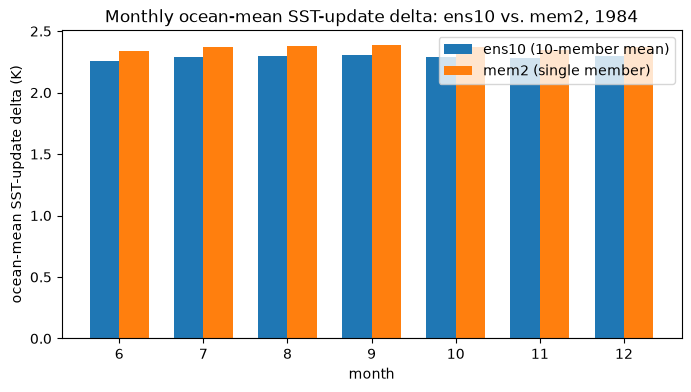

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
months = monthly.index.values
width = 0.35
ax.bar(months - width / 2, monthly["ens10_mean"], width, label="ens10 (10-member mean)")
ax.bar(months + width / 2, monthly["mem2_mean"], width, label="mem2 (single member)")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("month")
ax.set_ylabel("ocean-mean SST-update delta (K)")
ax.set_xticks(months)
ax.set_title("Monthly ocean-mean SST-update delta: ens10 vs. mem2, 1984")
ax.legend()
plt.show()

## B5. Spatial pattern agreement

For each month, the Pearson correlation between the two pipelines' delta *maps* (ocean cells only) measures how similar the large-scale warming pattern is; the RMS difference measures the typical local disagreement in magnitude -- largely the internal-variability "noise" a single member carries that the 10-member mean has averaged away.

In [17]:
rows = []
for month in months_present:
    corr, rms = corr_rms(ens10_deltas[month], mem2_deltas[month], ocean_mask)
    rows.append(dict(month=month, spatial_corr=corr, rms_diff_K=rms))
pattern_stats = pd.DataFrame(rows).set_index("month").round(3)
pattern_stats

,spatial_corr,rms_diff_K
month,,
6,0.995,0.153
7,0.991,0.175
8,0.992,0.168
9,0.993,0.155
10,0.994,0.146
11,0.994,0.145
12,0.995,0.142


## B6. Maps: ens10 vs. mem2 vs. their difference

One representative month (the first one common to both pipelines). Land is masked out -- SST is only meaningful over ocean.

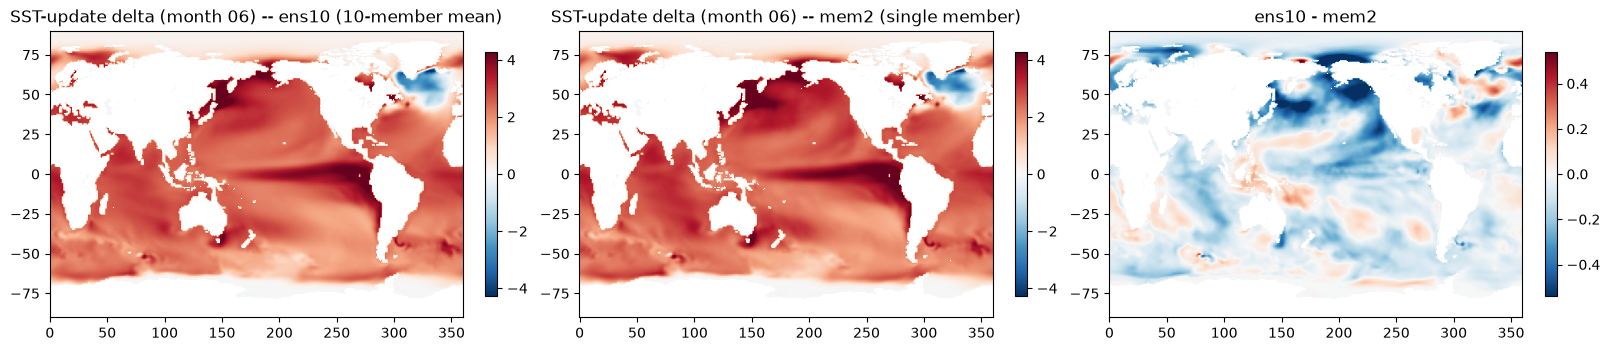

In [18]:
month0 = months_present[0]
plot_pair_diff(ens10_deltas[month0], mem2_deltas[month0], f"SST-update delta (month {month0:02d})",
               mask_land=True)

## B7. Seasonal cycle: ocean-mean delta across every common date

The intended delta is constant within a calendar month (it's a monthly climatology, B4), so this is necessarily a step function -- one flat level per month, stepping at each month boundary -- rather than genuine day-to-day variation. What it shows is the *seasonal cycle* of each pipeline's warming signal, and how far apart the two pipelines' seasonal cycles sit.

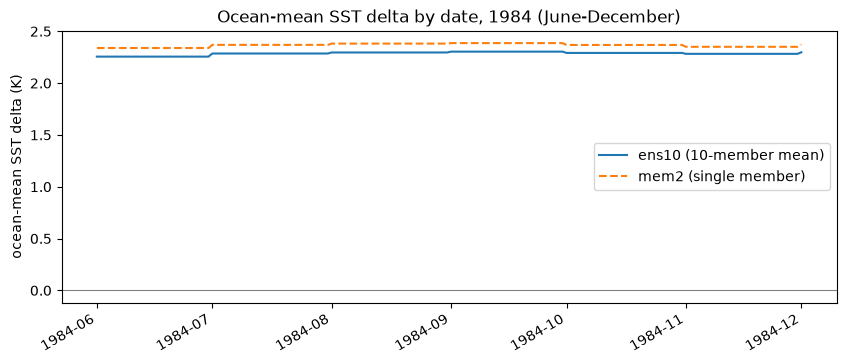

In [19]:
# datetime is only used here to get a proper date axis on the plot below
dates_dt = [dt.datetime.strptime(r["date"][:10], "%Y-%m-%d") for r in records]
ens10_ts = [area_wmean(ens10_deltas[r["month"]], ocean_mask) for r in records]
mem2_ts = [area_wmean(mem2_deltas[r["month"]], ocean_mask) for r in records]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dates_dt, ens10_ts, label="ens10 (10-member mean)", lw=1.5)
ax.plot(dates_dt, mem2_ts, label="mem2 (single member)", lw=1.5, ls="--")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylabel("ocean-mean SST delta (K)")
ax.set_title("Ocean-mean SST delta by date, 1984 (June-December)")
ax.legend()
fig.autofmt_xdate()
plt.show()

# Summary

**Part A (main `ERA5:1984-06-*` archive, 6 dates, June only)** -- area-weighted global means, ens10 vs. mem2:

| field | ens10 | mem2 | diff (ens10-mem2) | spatial corr | RMS diff |
|---|---|---|---|---|---|
| GHT @ 850 hPa | 22.14 m | 22.65 m | -0.51 m | 0.93 | 6.6 m |
| TT @ 850 hPa | 3.72 K | 3.77 K | -0.05 K | 0.96 | 0.32 K |
| RH @ 850 hPa | -2.43 % | -2.36 % | -0.07 % | 0.93 | 1.7 % |
| SKINTEMP | 3.22 K | 3.31 K | -0.09 K | 0.99 | 0.32 K |
| SST (ocean) | 2.26 K | 2.34 K | -0.08 K | 0.995 | 0.15 K |

- Surface fields (`SKINTEMP`, `SST`) agree almost as tightly here as in Part B (correlation 0.99+), and by the same small, consistent margin: mem2 running a few hundredths of a K warmer than ens10.
- The 3-D fields at 850 hPa agree less tightly (correlation 0.93-0.96) than the surface fields -- expected, since a single June's 850 hPa `GHT`/`RH` climatology carries more weather-scale spatial structure that 10-member averaging smooths out but a single member's climatology doesn't. `GHT`'s RMS difference (6.6 m) is proportionally the largest of the five fields relative to its own mean signal (~22 m, ~30%) -- worth keeping in mind if a run is sensitive to the *pattern* (not just the global mean) of the imposed geopotential perturbation. The A4 vertical-profile plot shows where up the column this agreement holds up or breaks down.
- All of this is from only 6 June dates (the only 1984 main-stream data either pipeline has), so treat it as indicative, not as statistically robust as the 184-day Part B result below.

**Part B (periodic SST-update stream, 184 dates, June-December)**:

- **Spatial pattern agreement is very high**: ocean-cell spatial correlation between the ens10 and mem2 delta maps is 0.99-0.995 in every month -- both pipelines are clearly driven by the same large-scale, externally-forced SSP370 warming pattern (e.g. the same land/ocean and high/low-latitude structure), not two unrelated signals.
- **Magnitude is close but not identical**: area-weighted ocean-mean delta runs 2.26-2.30 K (ens10) / 2.34-2.39 K (mem2) across the months. mem2 (single member) is consistently **~0.07-0.09 K warmer on average than ens10 (10-member mean)**, in every month -- small (roughly 3-4% of the signal) but systematic, not noise that flips sign month to month.
- **RMS spatial difference is small relative to the signal**: 0.14-0.18 K, versus a ~2 K mean signal -- consistent with mem2 carrying its own member-specific internal variability that the 10-member average has largely (not entirely) averaged out, layered on top of the shared forced signal both pipelines agree on.
- **Floor-clamping is a real minority, not a rounding footnote**: roughly a tenth of ocean-cell/date combinations hit the 271 K floor in both pipelines (B3) -- expected given how much Southern Ocean/Arctic water already sits near freezing, and consistent between the two pipelines rather than being specific to one.

**Net**: the single-member pipeline ("member 2") is a reasonable stand-in for the 10-member ensemble mean -- same large-scale pattern, magnitude within a few percent to ~5% depending on field -- but it is not a perfect substitute, since it carries small, systematic differences traceable to that one member's own realization of internal variability. If a run specifically needs the externally-forced signal isolated from a single member's own weather/decadal noise, the ensemble-mean (ens10) forcing is the more defensible choice; if the point of a run is instead to sample one physically plausible realization of 2065-2095 change, mem2's forcing remains appropriate on its own terms.